# Četvrti zadatak


Dodavanje biblioteka

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from numpy.linalg import inv, det

Gnerisanje 500 odbiraka

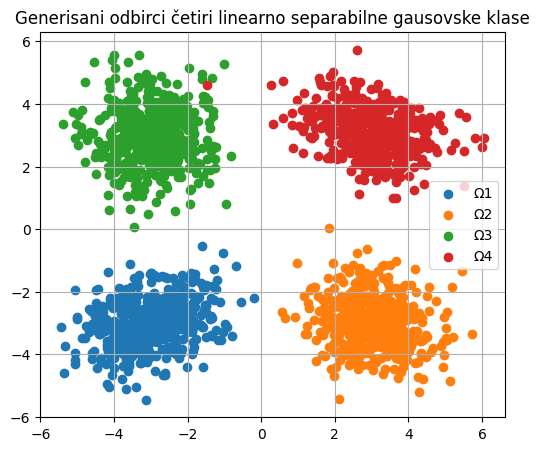

In [6]:
N = 500 

# prva klasa
M1 = np.array([-3,-3])
S1 = np.array([[0.8, 0.2],[0.2, 0.6]])
data1 = np.random.multivariate_normal(M1, S1, N)

# druga klasa
M2 = np.array([3,-3])
S2 = np.array([[0.7, -0.15],[-0.15, 0.7]])
data2 = np.random.multivariate_normal(M2, S2, N)

# treća klasa
M3 = np.array([-3,3])
S3 = np.array([[0.6, 0],[0, 0.9]])
data3 = np.random.multivariate_normal(M3, S3, N)

# četvrta klasa
M4 = np.array([3,3])
S4 = np.array([[0.9, -0.25],[-0.25, 0.6]])
data4 = np.random.multivariate_normal(M4, S4, N)

# crtanje
plt.figure(figsize=(6,5))
plt.scatter(data1[:, 0], data1[:, 1], label="Ω1")
plt.scatter(data2[:, 0], data2[:, 1], label="Ω2")
plt.scatter(data3[:, 0], data3[:, 1], label="Ω3")
plt.scatter(data4[:, 0], data4[:, 1], label="Ω4")

plt.title("Generisani odbirci četiri linearno separabilne gausovske klase")
plt.legend()
plt.grid(True)
plt.show()

C-mean klasterizacija

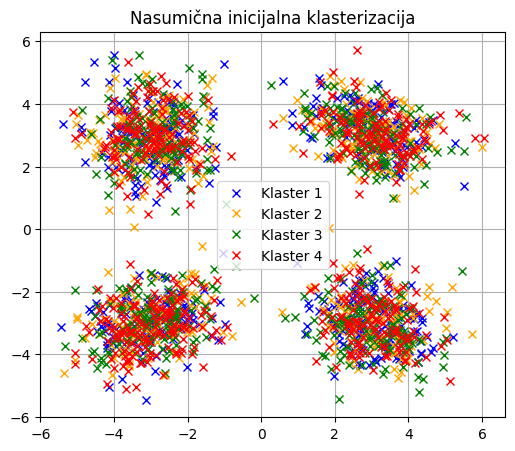

In [9]:
# K1
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 4, size=data.shape[1])

X1 = data[:, labels == 0]
X2 = data[:, labels == 1]
X3 = data[:, labels == 2]
X4 = data[:, labels == 3]

plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.plot(X4[0, :], X4[1, :], 'rx', label='Klaster 4')
plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.grid(True)
plt.show()

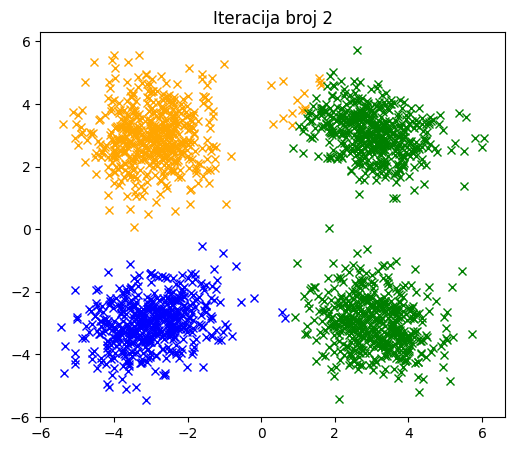

In [16]:
# K2

lmax = 50 
l = 0 
reclassified = True

while l < lmax and reclassified:
    # određivanje mat. očekivanja za svaki klaster
    M1 = np.mean(X1, axis=1).reshape(-1, 1)
    M2 = np.mean(X2, axis=1).reshape(-1, 1)
    M3 = np.mean(X3, axis=1).reshape(-1, 1)
    M4 = np.mean(X4, axis=1).reshape(-1, 1)
    # matrice za smeštanje odbiraka nakon reklasterizacije
    new_X1 = []
    new_X2 = []
    new_X3 = []
    new_X4 = []
    # na početku ništa nije reklasterizovano
    reclassified = False

    for i in range(X1.shape[1]):
        # euklidske distance svakog odbirka iz prve klase od centara svih klastera
        d1 = np.sum((X1[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X1[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X1[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X1[:, i].reshape(-1,1) - M4)**2)
        # pronalazak minimalnog euklidskog rastojanja i po potrebi reklasterizacija
        minimum = min(d1, d2, d3, d4)
        if d1 == minimum:
            new_X1.append(X1[:, i])
        elif d2== minimum:
            new_X2.append(X1[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X1[:, i])
            reclassified = True
        else:
            new_X4.append(X1[:, i])
            reclassified = True
            
    # Analogni postupak i za odbirke svih ostalih klasa
    for i in range(X2.shape[1]):
        d1 = np.sum((X2[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X2[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X2[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X2[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d2 == minimum:
            new_X2.append(X2[:, i])
        elif d1== minimum:
            new_X1.append(X2[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X2[:, i])
            reclassified = True
        else:
            new_X4.append(X2[:, i])
            reclassified = True

    for i in range(X3.shape[1]):
        d1 = np.sum((X3[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X3[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X3[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X3[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d3 == minimum:
            new_X3.append(X3[:, i])
        elif d1== minimum:
            new_X1.append(X3[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X3[:, i])
            reclassified = True
        else:
            new_X4.append(X3[:, i])
            reclassified = True

    for i in range(X4.shape[1]):
        d1 = np.sum((X4[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X4[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X4[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X4[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d4 == minimum:
            new_X4.append(X4[:, i])
        elif d1== minimum:
            new_X1.append(X4[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X4[:, i])
            reclassified = True
        else:
            new_X3.append(X4[:, i])
            reclassified = True

   
    X1 = np.array(new_X1).T if new_X1 else np.empty((X1.shape[0], 0))
    X2 = np.array(new_X2).T if new_X2 else np.empty((X2.shape[0], 0))
    X3 = np.array(new_X3).T if new_X3 else np.empty((X3.shape[0], 0))
    X4 = np.array(new_X4).T if new_X4 else np.empty((X4.shape[0], 0))
      
    l += 1


plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.plot(X4[0, :], X4[1, :], 'rx', label='Klaster 4')
plt.title(f'Iteracija broj {l+1}')
plt.show()

Srednji broj potrebnih iteracija

Prosečan broj iteracija je 6


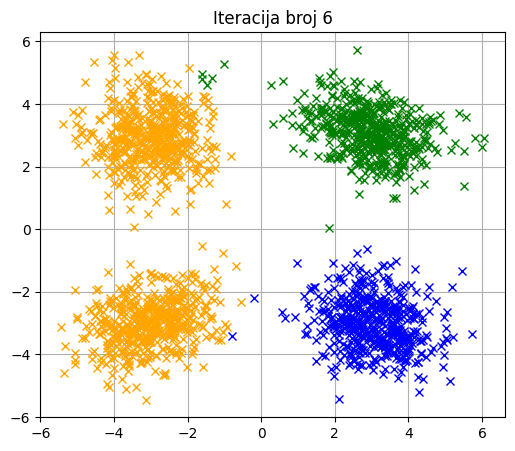

In [21]:
lsum = 0
for i in range(20):
    # u svakoj iteraciji nova inicijalna klasterizacija
    data = np.vstack((data1, data2, data3, data4)).T  
    labels = np.random.randint(0, 4, size=data.shape[1])
    
    X1 = data[:, labels == 0]
    X2 = data[:, labels == 1]
    X3 = data[:, labels == 2]
    X4 = data[:, labels == 3]
    lmax = 50 
    l = 0 
    reclassified = True
    
    while l < lmax and reclassified:
        M1 = np.mean(X1, axis=1).reshape(-1, 1)
        M2 = np.mean(X2, axis=1).reshape(-1, 1)
        M3 = np.mean(X3, axis=1).reshape(-1, 1)
        M4 = np.mean(X4, axis=1).reshape(-1, 1)
        new_X1 = []
        new_X2 = []
        new_X3 = []
        new_X4 = []
        reclassified = False
    
        for i in range(X1.shape[1]):
            d1 = np.sum((X1[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X1[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X1[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X1[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d1 == minimum:
                new_X1.append(X1[:, i])
            elif d2== minimum:
                new_X2.append(X1[:, i])
                reclassified = True
            elif d3== minimum:
                new_X3.append(X1[:, i])
                reclassified = True
            else:
                new_X4.append(X1[:, i])
                reclassified = True
                
        for i in range(X2.shape[1]):
            d1 = np.sum((X2[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X2[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X2[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X2[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d2 == minimum:
                new_X2.append(X2[:, i])
            elif d1== minimum:
                new_X1.append(X2[:, i])
                reclassified = True
            elif d3== minimum:
                new_X3.append(X2[:, i])
                reclassified = True
            else:
                new_X4.append(X2[:, i])
                reclassified = True
    
        for i in range(X3.shape[1]):
            d1 = np.sum((X3[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X3[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X3[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X3[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d3 == minimum:
                new_X3.append(X3[:, i])
            elif d1== minimum:
                new_X1.append(X3[:, i])
                reclassified = True
            elif d2== minimum:
                new_X2.append(X3[:, i])
                reclassified = True
            else:
                new_X4.append(X3[:, i])
                reclassified = True
    
        for i in range(X4.shape[1]):
            d1 = np.sum((X4[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X4[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X4[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X4[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d4 == minimum:
                new_X4.append(X4[:, i])
            elif d1== minimum:
                new_X1.append(X4[:, i])
                reclassified = True
            elif d2== minimum:
                new_X2.append(X4[:, i])
                reclassified = True
            else:
                new_X3.append(X4[:, i])
                reclassified = True
    
       
        X1 = np.array(new_X1).T if new_X1 else np.empty((X1.shape[0], 0))
        X2 = np.array(new_X2).T if new_X2 else np.empty((X2.shape[0], 0))
        X3 = np.array(new_X3).T if new_X3 else np.empty((X3.shape[0], 0))
        X4 = np.array(new_X4).T if new_X4 else np.empty((X4.shape[0], 0))
      
        l += 1
    lsum+=l

lmid=round(lsum/20)
print(f"Prosečan broj iteracija je {lmid}")

plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.plot(X4[0, :], X4[1, :], 'rx', label='Klaster 4')
plt.title(f'Iteracija broj {l+1}')
plt.grid(True)
plt.show()


Rezultat 2: klasterizacija nije potpuno stohastička

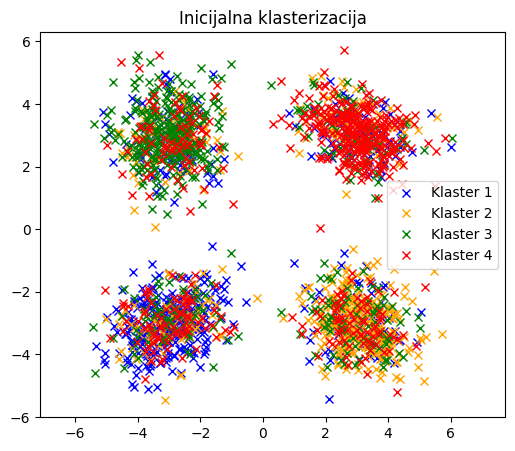

In [29]:
# po 200 odbiraka iz svake klase fiksiramo u tacnu klasu kojoj pripadaju
fixed = 200

X1a = data1[:fixed, :].T
X2a = data2[:fixed, :].T
X3a = data3[:fixed, :].T
X4a = data4[:fixed, :].T

remaining = np.vstack((
    data1[fixed:, :],
    data2[fixed:, :],
    data3[fixed:, :],
    data4[fixed:, :]
))

labels = np.random.randint(0, 4, size=remaining.shape[0])
X1a = np.hstack((X1a, remaining[labels == 0].T))
X2a = np.hstack((X2a, remaining[labels == 1].T))
X3a = np.hstack((X3a, remaining[labels == 2].T))
X4a = np.hstack((X4a, remaining[labels == 3].T))

plt.figure(figsize=(6,5))
plt.plot(X1a[0, :], X1a[1, :], 'bx', label='Klaster 1')
plt.plot(X2a[0, :], X2a[1, :], 'x', color='orange', label='Klaster 2')
plt.plot(X3a[0, :], X3a[1, :], 'gx', label='Klaster 3')
plt.plot(X4a[0, :], X4a[1, :], 'rx', label='Klaster 4')
plt.axis('equal')
plt.title('Inicijalna klasterizacija')
plt.legend()
plt.show()

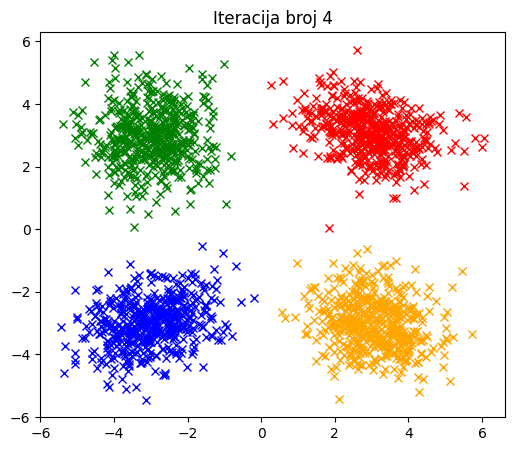

In [30]:
# identičan postupak kao kada je potpuno stohastička inicijalizacija
lmax = 50 
l = 0 
reclassified = True

while l < lmax and reclassified:
    M1 = np.mean(X1a, axis=1).reshape(-1, 1)
    M2 = np.mean(X2a, axis=1).reshape(-1, 1)
    M3 = np.mean(X3a, axis=1).reshape(-1, 1)
    M4 = np.mean(X4a, axis=1).reshape(-1, 1)
    new_X1 = []
    new_X2 = []
    new_X3 = []
    new_X4 = []
    reclassified = False

    for i in range(X1a.shape[1]):
        d1 = np.sum((X1a[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X1a[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X1a[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X1a[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d1 == minimum:
            new_X1.append(X1a[:, i])
        elif d2== minimum:
            new_X2.append(X1a[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X1a[:, i])
            reclassified = True
        else:
            new_X4.append(X1a[:, i])
            reclassified = True
            
    for i in range(X2a.shape[1]):
        d1 = np.sum((X2a[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X2a[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X2a[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X2a[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d2 == minimum:
            new_X2.append(X2a[:, i])
        elif d1== minimum:
            new_X1.append(X2a[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X2a[:, i])
            reclassified = True
        else:
            new_X4.append(X2a[:, i])
            reclassified = True

    for i in range(X3a.shape[1]):
        d1 = np.sum((X3a[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X3a[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X3a[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X3a[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d3 == minimum:
            new_X3.append(X3a[:, i])
        elif d1== minimum:
            new_X1.append(X3a[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X3a[:, i])
            reclassified = True
        else:
            new_X4.append(X3a[:, i])
            reclassified = True

    for i in range(X4a.shape[1]):
        d1 = np.sum((X4a[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X4a[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X4a[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X4a[:, i].reshape(-1,1) - M4)**2)
        minimum = min(d1, d2, d3, d4)
        if d4 == minimum:
            new_X4.append(X4a[:, i])
        elif d1== minimum:
            new_X1.append(X4a[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X4a[:, i])
            reclassified = True
        else:
            new_X3.append(X4a[:, i])
            reclassified = True

    X1a = np.array(new_X1).T if new_X1 else np.empty((X1a.shape[0], 0))
    X2a = np.array(new_X2).T if new_X2 else np.empty((X2a.shape[0], 0))
    X3a = np.array(new_X3).T if new_X3 else np.empty((X3a.shape[0], 0))
    X4a = np.array(new_X4).T if new_X4 else np.empty((X4a.shape[0], 0))
  
    l += 1
    
plt.figure(figsize=(6, 5))
plt.plot(X1a[0, :], X1a[1, :], 'bx', label='Klaster 1')
plt.plot(X2a[0, :], X2a[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3a[0, :], X3a[1, :], 'gx', label='Klaster 3')
plt.plot(X4a[0, :], X4a[1, :], 'rx', label='Klaster 4')
plt.title(f'Iteracija broj {l+1}')
plt.show()

In [24]:
# prosečan broj iteracija

lsum = 0
for i in range(20):
    fixed = 200

    X1a = data1[:fixed, :].T
    X2a = data2[:fixed, :].T
    X3a = data3[:fixed, :].T
    X4a = data4[:fixed, :].T
    
    remaining = np.vstack((
        data1[fixed:, :],
        data2[fixed:, :],
        data3[fixed:, :],
        data4[fixed:, :]
    ))
    
    labels = np.random.randint(0, 4, size=remaining.shape[0])
    X1a = np.hstack((X1a, remaining[labels == 0].T))
    X2a = np.hstack((X2a, remaining[labels == 1].T))
    X3a = np.hstack((X3a, remaining[labels == 2].T))
    X4a = np.hstack((X4a, remaining[labels == 3].T))

    lmax = 50 
    l = 0 
    reclassified = True
    
    while l < lmax and reclassified:
        M1 = np.mean(X1a, axis=1).reshape(-1, 1)
        M2 = np.mean(X2a, axis=1).reshape(-1, 1)
        M3 = np.mean(X3a, axis=1).reshape(-1, 1)
        M4 = np.mean(X4a, axis=1).reshape(-1, 1)
        new_X1 = []
        new_X2 = []
        new_X3 = []
        new_X4 = []
        reclassified = False
    
        for i in range(X1a.shape[1]):
            d1 = np.sum((X1a[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X1a[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X1a[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X1a[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d1 == minimum:
                new_X1.append(X1a[:, i])
            elif d2== minimum:
                new_X2.append(X1a[:, i])
                reclassified = True
            elif d3== minimum:
                new_X3.append(X1a[:, i])
                reclassified = True
            else:
                new_X4.append(X1a[:, i])
                reclassified = True
                
        for i in range(X2a.shape[1]):
            d1 = np.sum((X2a[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X2a[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X2a[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X2a[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d2 == minimum:
                new_X2.append(X2a[:, i])
            elif d1== minimum:
                new_X1.append(X2a[:, i])
                reclassified = True
            elif d3== minimum:
                new_X3.append(X2a[:, i])
                reclassified = True
            else:
                new_X4.append(X2a[:, i])
                reclassified = True
    
        for i in range(X3a.shape[1]):
            d1 = np.sum((X3a[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X3a[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X3a[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X3a[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d3 == minimum:
                new_X3.append(X3a[:, i])
            elif d1== minimum:
                new_X1.append(X3a[:, i])
                reclassified = True
            elif d2== minimum:
                new_X2.append(X3a[:, i])
                reclassified = True
            else:
                new_X4.append(X3a[:, i])
                reclassified = True
    
        for i in range(X4a.shape[1]):
            d1 = np.sum((X4a[:, i].reshape(-1,1) - M1)**2)
            d2 = np.sum((X4a[:, i].reshape(-1,1) - M2)**2)
            d3 = np.sum((X4a[:, i].reshape(-1,1) - M3)**2)
            d4 = np.sum((X4a[:, i].reshape(-1,1) - M4)**2)
            minimum = min(d1, d2, d3, d4)
            if d4 == minimum:
                new_X4.append(X4a[:, i])
            elif d1== minimum:
                new_X1.append(X4a[:, i])
                reclassified = True
            elif d2== minimum:
                new_X2.append(X4a[:, i])
                reclassified = True
            else:
                new_X3.append(X4a[:, i])
                reclassified = True
    
        X1a = np.array(new_X1).T if new_X1 else np.empty((X1a.shape[0], 0))
        X2a = np.array(new_X2).T if new_X2 else np.empty((X2a.shape[0], 0))
        X3a = np.array(new_X3).T if new_X3 else np.empty((X3a.shape[0], 0))
        X4a = np.array(new_X4).T if new_X4 else np.empty((X4a.shape[0], 0))
      
        l += 1
        
    

    lsum+=l

lmid=round(lsum/20)
print(f"Prosečan broj iteracija je {lmid}")

Prosečan broj iteracija je 3


Rezultat 3: apriorno ne znamo broj klasa (pretpostavimo da je 3)

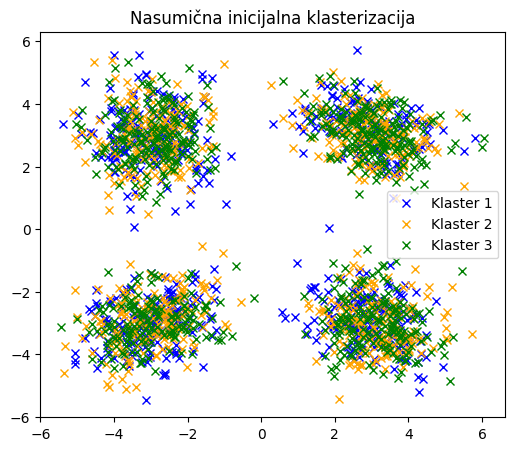

In [31]:
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 3, size=data.shape[1])

X1 = data[:, labels == 0]
X2 = data[:, labels == 1]
X3 = data[:, labels == 2]

plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.show()

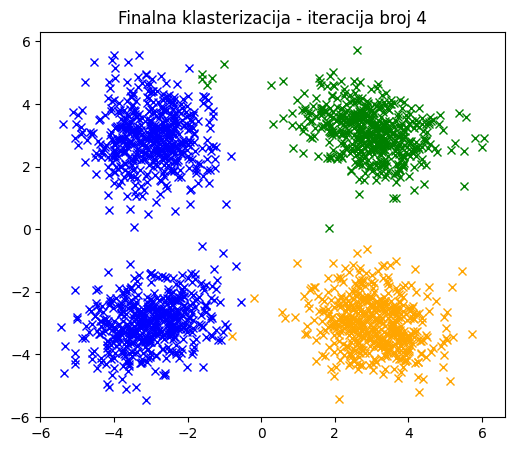

In [32]:
lmax = 50 
l = 0 
reclassified = True

while l < lmax and reclassified:
    M1 = np.mean(X1, axis=1).reshape(-1, 1)
    M2 = np.mean(X2, axis=1).reshape(-1, 1)
    M3 = np.mean(X3, axis=1).reshape(-1, 1)
    new_X1 = []
    new_X2 = []
    new_X3 = []
    reclassified = False

    for i in range(X1.shape[1]):
        d1 = np.sum((X1[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X1[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X1[:, i].reshape(-1,1) - M3)**2)
        minimum = min(d1, d2, d3)
        if d1 == minimum:
            new_X1.append(X1[:, i])
        elif d2== minimum:
            new_X2.append(X1[:, i])
            reclassified = True
        else:
            new_X3.append(X1[:, i])
            reclassified = True
            
    for i in range(X2.shape[1]):
        d1 = np.sum((X2[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X2[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X2[:, i].reshape(-1,1) - M3)**2)
        minimum = min(d1, d2, d3)
        if d2 == minimum:
            new_X2.append(X2[:, i])
        elif d1== minimum:
            new_X1.append(X2[:, i])
            reclassified = True
        else:
            new_X3.append(X2[:, i])
            reclassified = True


    for i in range(X3.shape[1]):
        d1 = np.sum((X3[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X3[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X3[:, i].reshape(-1,1) - M3)**2)
        minimum = min(d1, d2, d3)
        if d3 == minimum:
            new_X3.append(X3[:, i])
        elif d1== minimum:
            new_X1.append(X3[:, i])
            reclassified = True
        else:
            new_X2.append(X3[:, i])
            reclassified = True

    X1 = np.array(new_X1).T if new_X1 else np.empty((X1.shape[0], 0))
    X2 = np.array(new_X2).T if new_X2 else np.empty((X2.shape[0], 0))
    X3 = np.array(new_X3).T if new_X3 else np.empty((X3.shape[0], 0))  
    l += 1
    
plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.title(f'Finalna klasterizacija - iteracija broj {l+1}')
plt.show()

Rezultat 4: aprorno ne poznajemo broj klasa (pretpostavimo 5)

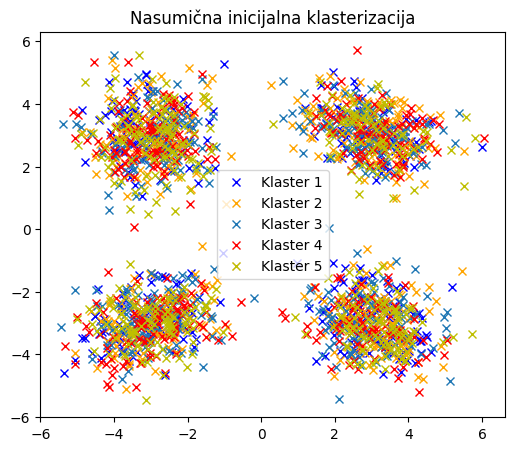

In [33]:
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 5, size=data.shape[1])

X1 = data[:, labels == 0]
X2 = data[:, labels == 1]
X3 = data[:, labels == 2]
X4 = data[:, labels == 3]
X5 = data[:, labels == 4]

plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'x', label='Klaster 3')
plt.plot(X4[0, :], X4[1, :], 'rx', label='Klaster 4')
plt.plot(X5[0, :], X5[1, :], 'yx', label='Klaster 5')

plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.show()

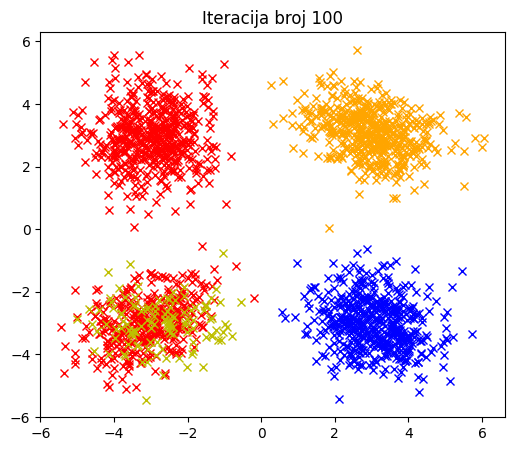

In [34]:
lmax = 100 
l = 0 
reclassified = True

while l < lmax and reclassified:
    M1 = np.mean(X1, axis=1).reshape(-1, 1)
    M2 = np.mean(X2, axis=1).reshape(-1, 1)
    M3 = np.mean(X3, axis=1).reshape(-1, 1)
    M4 = np.mean(X4, axis=1).reshape(-1, 1)
    M5 = np.mean(X5, axis=1).reshape(-1, 1)

    new_X1 = []
    new_X2 = []
    new_X3 = []
    new_X4 = []
    new_X5 = []
    reclassified = False

    for i in range(X1.shape[1]):
        d1 = np.sum((X1[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X1[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X1[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X1[:, i].reshape(-1,1) - M4)**2)
        d5 = np.sum((X1[:, i].reshape(-1,1) - M5)**2)
        minimum = min(d1, d2, d3, d4,d5)
        if d1 == minimum:
            new_X1.append(X1[:, i])
        elif d2== minimum:
            new_X2.append(X1[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X1[:, i])
            reclassified = True
        elif d4== minimum:
            new_X4.append(X1[:, i])
            reclassified = True
        else:
            new_X5.append(X1[:, i])
            reclassified = True
            
    for i in range(X2.shape[1]):
        d1 = np.sum((X2[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X2[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X2[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X2[:, i].reshape(-1,1) - M4)**2)
        d5 = np.sum((X2[:, i].reshape(-1,1) - M5)**2)
        minimum = min(d1, d2, d3, d4,d5)
        if d2 == minimum:
            new_X2.append(X2[:, i])
        elif d1== minimum:
            new_X1.append(X2[:, i])
            reclassified = True
        elif d3== minimum:
            new_X3.append(X2[:, i])
            reclassified = True
        elif d4== minimum:
            new_X4.append(X2[:, i])
            reclassified = True
        else:
            new_X5.append(X2[:, i])
            reclassified = True

    for i in range(X3.shape[1]):
        d1 = np.sum((X3[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X3[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X3[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X3[:, i].reshape(-1,1) - M4)**2)
        d5 = np.sum((X3[:, i].reshape(-1,1) - M5)**2)
        minimum = min(d1, d2, d3, d4, d5)
        if d3 == minimum:
            new_X3.append(X3[:, i])
        elif d1== minimum:
            new_X1.append(X3[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X3[:, i])
            reclassified = True
        elif d4== minimum:
            new_X4.append(X3[:, i])
            reclassified = True
        else:
            new_X5.append(X3[:, i])
            reclassified = True

    for i in range(X4.shape[1]):
        d1 = np.sum((X4[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X4[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X4[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X4[:, i].reshape(-1,1) - M4)**2)
        d5 = np.sum((X4[:, i].reshape(-1,1) - M5)**2)
        minimum = min(d1, d2, d3, d4, d5)
        if d4 == minimum:
            new_X4.append(X4[:, i])
        elif d1== minimum:
            new_X1.append(X4[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X4[:, i])
            reclassified = True
        elif d3==minimum:
            new_X3.append(X4[:, i])
            reclassified = True
        else:
            new_X5.append(X4[:, i])
            reclassified=True

    for i in range(X5.shape[1]):
        d1 = np.sum((X5[:, i].reshape(-1,1) - M1)**2)
        d2 = np.sum((X5[:, i].reshape(-1,1) - M2)**2)
        d3 = np.sum((X5[:, i].reshape(-1,1) - M3)**2)
        d4 = np.sum((X5[:, i].reshape(-1,1) - M4)**2)
        d5 = np.sum((X5[:, i].reshape(-1,1) - M5)**2)
        minimum = min(d1, d2, d3, d4, d5)
        if d5 == minimum:
            new_X4.append(X5[:, i])
        elif d1== minimum:
            new_X1.append(X5[:, i])
            reclassified = True
        elif d2== minimum:
            new_X2.append(X5[:, i])
            reclassified = True
        elif d3==minimum:
            new_X3.append(X5[:, i])
            reclassified = True
        else:
            new_X4.append(X5[:, i])
            reclassified=True

   
    X1 = np.array(new_X1).T if new_X1 else np.empty((X1.shape[0], 0))
    X2 = np.array(new_X2).T if new_X2 else np.empty((X2.shape[0], 0))
    X3 = np.array(new_X3).T if new_X3 else np.empty((X3.shape[0], 0))
    X4 = np.array(new_X4).T if new_X4 else np.empty((X4.shape[0], 0))
    X5 = np.array(new_X5).T if new_X5 else np.empty((X5.shape[0], 0))
  
    l += 1
    
plt.figure(figsize=(6, 5))
plt.plot(X1[0, :], X1[1, :], 'bx', label='Klaster 1')
plt.plot(X2[0, :], X2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(X3[0, :], X3[1, :], 'gx', label='Klaster 3')
plt.plot(X4[0, :], X4[1, :], 'rx', label='Klaster 4')
plt.plot(X5[0, :], X5[1, :], 'yx', label='Klaster 5')
plt.title(f'Iteracija broj {l}')
plt.show()

MLE metoda

Rezultat 1 za stohastičku inicajlnu klasterizaciju sa poznatim brojem klastera

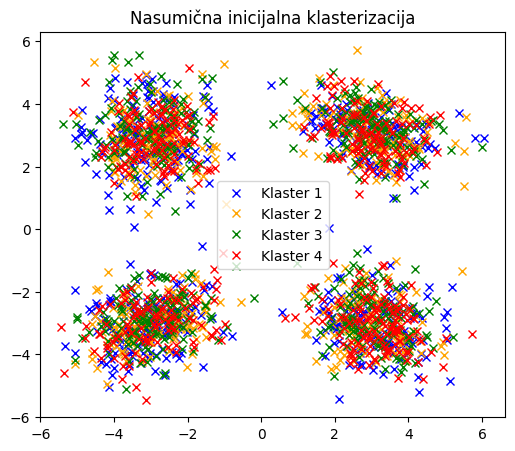

In [35]:
# K1
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 4, size=data.shape[1])

K1 = data[:, labels == 0]
K2 = data[:, labels == 1]
K3 = data[:, labels == 2]
K4 = data[:, labels == 3]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.plot(K4[0, :], K4[1, :], 'rx', label='Klaster 4')
plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.show()

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:68: RuntimeWarning: divide by zero encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:68: RuntimeWarning: overflow encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/39

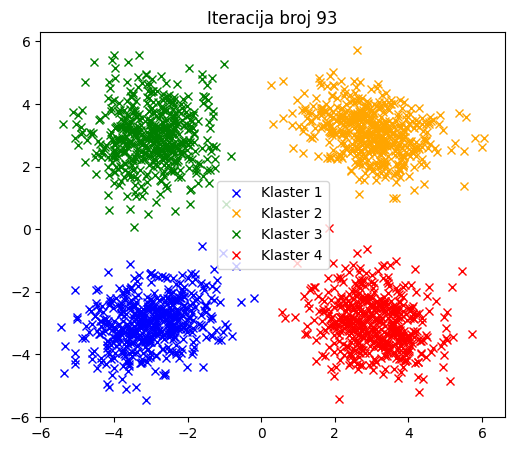

In [38]:
# K2: Inicijalna procena vrednosti M, S i P za svaku od klasa

M1 = np.mean(K1, axis=1)  
S1 = np.cov(K1)
P1 = K1.shape[1] / (4 * N)

M2 = np.mean(K2, axis=1)
S2 = np.cov(K2)
P2 = K2.shape[1] / (4 * N)

M3 = np.mean(K3, axis=1)
S3 = np.cov(K3)
P3 = K3.shape[1] / (4 * N)

M4 = np.mean(K4, axis=1)
S4 = np.cov(K4)
P4 = K4.shape[1] / (4 * N)

# funkcija za Gausovsku fgv
def multivar_gauss(x, mean, cov):
    size = mean.shape[0]
    det_cov = np.linalg.det(cov)
    inv_cov = np.linalg.inv(cov)
    diff = x - mean[:, np.newaxis]  
    exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
    coef = 1 / (2 * np.pi * det_cov)**0.5
    return coef * np.exp(exponent)

# računanje fi(xj)
K = np.hstack((K1, K2, K3, K4))
f1 = multivar_gauss(K, M1, S1)
f2 = multivar_gauss(K, M2, S2)
f3 = multivar_gauss(K, M3, S3)
f4 = multivar_gauss(K, M4, S4)

# Računanje qi(xj)
denom = P1*f1 + P2*f2 + P3*f3 + P4*f4
q1 = P1 * f1 / denom
q2 = P2 * f2 / denom
q3 = P3 * f3 / denom
q4 = P4 * f4 / denom

# predefinisanje promenljivih 
lmax = 100
l = 0 
reclassified = True 
T = 1e-8

while l<lmax and reclassified:    
    # ažuriranje Pi
    P1 = np.sum(q1) / (4*N)
    P2 = np.sum(q2) / (4*N)
    P3 = np.sum(q3) / (4*N)
    P4 = np.sum(q4) / (4*N)

    # ažuriranje Mi
    M1 = np.sum(q1 * K, axis=1) / (P1 * 4*N) 
    M2 = np.sum(q2 * K, axis=1) / (P2 * 4*N)
    M3 = np.sum(q3 * K, axis=1) / (P3 * 4*N)
    M4 = np.sum(q4 * K, axis=1) / (P4 * 4*N)
    
    # ažuriranje Si 
    diff1 = K - M1[:, np.newaxis]
    diff2 = K - M2[:, np.newaxis]
    diff3 = K - M3[:, np.newaxis]
    diff4 = K - M4[:, np.newaxis]
    
    S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
    S2 = (diff2 * q2) @ diff2.T / (P2 * 4*N)
    S3 = (diff3 * q3) @ diff3.T / (P3 * 4*N)
    S4 = (diff4 * q4) @ diff4.T / (P4 * 4*N)

    # računanje fi
    f1 = multivar_gauss(K, M1, S1)
    f2 = multivar_gauss(K, M2, S2)
    f3 = multivar_gauss(K, M3, S3)
    f4 = multivar_gauss(K, M4, S4)
    
    # računanje novih qi 
    sth = P1*f1 + P2*f2 + P3*f3 + P4*f4
    q1new = P1 * f1 / sth
    q2new = P2 * f2 / sth
    q3new = P3 * f3 / sth
    q4new = P4 * f4 / sth


    # reklasterizacija (ako je potrebna)
    l+=1
    q = np.vstack([q1, q2, q3, q4])
    qnew = np.vstack([q1new, q2new, q3new, q4new])
    if np.max(np.abs(qnew - q)) < T:
        reclassified = False
    else:
        # priprema za sledeću iteraciju
        q1 = q1new
        q2 = q2new
        q3 = q3new
        q4 = q4new

K1, K2, K3, K4 = [], [], [], []
q = np.vstack([q1new, q2new, q3new, q4new])

# svaki odbirak sme tamo gde mu je vrednost qi maksimalna
classes = np.argmax(q, axis=0) 

K1 = K[:, classes == 0]
K2 = K[:, classes == 1]
K3 = K[:, classes == 2]
K4 = K[:, classes == 3]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.plot(K4[0, :], K4[1, :], 'rx', label='Klaster 4')
plt.title(f'Iteracija broj {l}')
plt.legend()
plt.show()

In [39]:
# Prosečan broj iteracija

lsum = 0
for i in range(20):
    data = np.vstack((data1, data2, data3, data4)).T  
    labels = np.random.randint(0, 4, size=data.shape[1])
    
    K1 = data[:, labels == 0]
    K2 = data[:, labels == 1]
    K3 = data[:, labels == 2]
    K4 = data[:, labels == 3]
    
    M1 = np.mean(K1, axis=1) 
    S1 = np.cov(K1)
    P1 = K1.shape[1] / (4 * N)
    M2 = np.mean(K2, axis=1)
    S2 = np.cov(K2)
    P2 = K2.shape[1] / (4 * N)
    M3 = np.mean(K3, axis=1)
    S3 = np.cov(K3)
    P3 = K3.shape[1] / (4 * N)
    M4 = np.mean(K4, axis=1)
    S4 = np.cov(K4)
    P4 = K4.shape[1] / (4 * N)
    
    K = np.hstack((K1, K2, K3, K4))
    f1 = multivar_gauss(K, M1, S1)
    f2 = multivar_gauss(K, M2, S2)
    f3 = multivar_gauss(K, M3, S3)
    f4 = multivar_gauss(K, M4, S4)
    denom = P1*f1 + P2*f2 + P3*f3 + P4*f4
    q1 = P1 * f1 / denom
    q2 = P2 * f2 / denom
    q3 = P3 * f3 / denom
    q4 = P4 * f4 / denom

    lmax = 50 
    l = 0 
    reclassified = True 
    T = 1e-8
    
    while l<lmax and reclassified:    
        P1 = np.sum(q1) / (4*N)
        P2 = np.sum(q2) / (4*N)
        P3 = np.sum(q3) / (4*N)
        P4 = np.sum(q4) / (4*N)
    
        M1 = np.sum(q1 * K, axis=1) / (P1 * 4*N) 
        M2 = np.sum(q2 * K, axis=1) / (P2 * 4*N)
        M3 = np.sum(q3 * K, axis=1) / (P3 * 4*N)
        M4 = np.sum(q4 * K, axis=1) / (P4 * 4*N)
        
        diff1 = K - M1[:, np.newaxis]
        diff2 = K - M2[:, np.newaxis]
        diff3 = K - M3[:, np.newaxis]
        diff4 = K - M4[:, np.newaxis]
        
        S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
        S2 = (diff2 * q2) @ diff2.T / (P2 * 4*N)
        S3 = (diff3 * q3) @ diff3.T / (P3 * 4*N)
        S4 = (diff4 * q4) @ diff4.T / (P4 * 4*N)
    
        f1 = multivar_gauss(K, M1, S1)
        f2 = multivar_gauss(K, M2, S2)
        f3 = multivar_gauss(K, M3, S3)
        f4 = multivar_gauss(K, M4, S4)
        
        sth = P1*f1 + P2*f2 + P3*f3 + P4*f4
        q1new = P1 * f1 / sth
        q2new = P2 * f2 / sth
        q3new = P3 * f3 / sth
        q4new = P4 * f4 / sth
    
        l+=1
        q = np.vstack([q1, q2, q3, q4])
        qnew = np.vstack([q1new, q2new, q3new, q4new])
        if np.max(np.abs(qnew - q)) < T:
            reclassified = False
        else:
            q1 = q1new
            q2 = q2new
            q3 = q3new
            q4 = q4new
    lsum+=l

lmid=round(lsum/20)
print(f"Prosečan broj iteracija je {lmid}")

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3950072293.py:25: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/2528533055.py:58: RuntimeWarning: divide by zero encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/2528533055.py:58: RuntimeWarning: overflow encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/25

Prosečan broj iteracija je 50


Rezultat 2 (klasterizacija nije potpuno stohastička)

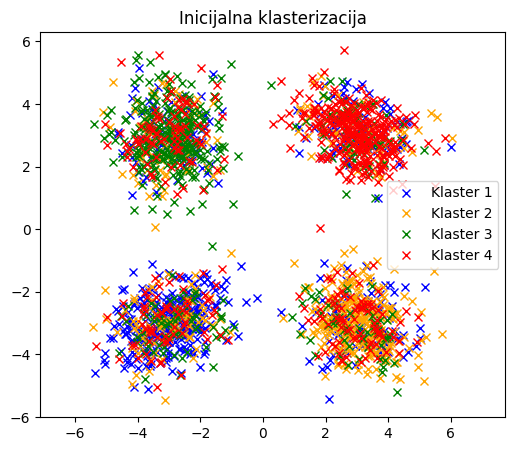

In [41]:
fixed = 200

K1a = data1[:fixed, :].T
K2a = data2[:fixed, :].T
K3a = data3[:fixed, :].T
K4a = data4[:fixed, :].T

remaining = np.vstack((
    data1[fixed:, :],
    data2[fixed:, :],
    data3[fixed:, :],
    data4[fixed:, :]
))

labels = np.random.randint(0, 4, size=remaining.shape[0])
K1a = np.hstack((K1a, remaining[labels == 0].T))
K2a = np.hstack((K2a, remaining[labels == 1].T))
K3a = np.hstack((K3a, remaining[labels == 2].T))
K4a = np.hstack((K4a, remaining[labels == 3].T))

plt.figure(figsize=(6,5))
plt.plot(K1a[0, :], K1a[1, :], 'bx', label='Klaster 1')
plt.plot(K2a[0, :], K2a[1, :], 'x', color='orange', label='Klaster 2')
plt.plot(K3a[0, :], K3a[1, :], 'gx', label='Klaster 3')
plt.plot(K4a[0, :], K4a[1, :], 'rx', label='Klaster 4')
plt.axis('equal')
plt.title('Inicijalna klasterizacija')
plt.legend()
plt.show()

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1156589727.py:47: RuntimeWarning: divide by zero encountered in matmul
  S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1156589727.py:47: RuntimeWarning: overflow encountered in matmul
  S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_4

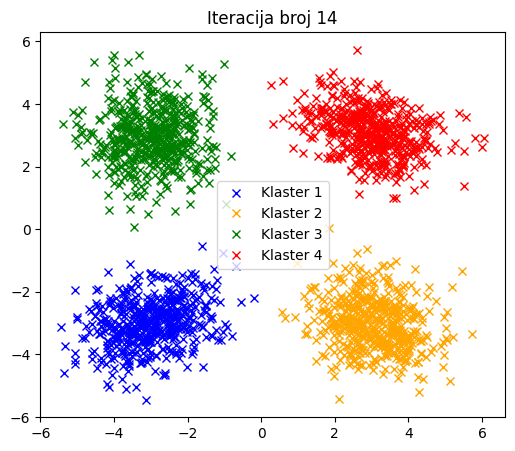

In [42]:
# identičan postupak kao gore
M1a = np.mean(K1a, axis=1)  
S1a = np.cov(K1a)
P1a = K1a.shape[1] / (4 * N)
M2a = np.mean(K2a, axis=1)
S2a = np.cov(K2a)
P2a = K2a.shape[1] / (4 * N)
M3a = np.mean(K3a, axis=1)
S3a = np.cov(K3a)
P3a = K3a.shape[1] / (4 * N)
M4a = np.mean(K4a, axis=1)
S4a = np.cov(K4a)
P4a = K4a.shape[1] / (4 * N)

Ka = np.hstack((K1, K2, K3, K4))
f1a = multivar_gauss(Ka, M1a, S1a)
f2a = multivar_gauss(Ka, M2a, S2a)
f3a = multivar_gauss(Ka, M3a, S3a)
f4a = multivar_gauss(Ka, M4a, S4a)
denom = P1a*f1a + P2a*f2a + P3a*f3a+ P4a*f4a
q1a = P1a * f1a / denom
q2a = P2a * f2a / denom
q3a = P3a * f3a / denom
q4a = P4a * f4a / denom

lmax = 50 
l = 0 
reclassified = True 
T = 1e-8

while l < lmax and reclassified:    
    P1a = np.sum(q1a) / (4*N)
    P2a = np.sum(q2a) / (4*N)
    P3a = np.sum(q3a) / (4*N)
    P4a = np.sum(q4a) / (4*N)

    M1a = np.sum(q1a * Ka, axis=1) / (P1a * 4*N) 
    M2a = np.sum(q2a * Ka, axis=1) / (P2a * 4*N)
    M3a = np.sum(q3a * Ka, axis=1) / (P3a * 4*N)
    M4a = np.sum(q4a * Ka, axis=1) / (P4a * 4*N)
    
    diff1a = Ka - M1a[:, np.newaxis]
    diff2a = Ka - M2a[:, np.newaxis]
    diff3a = Ka - M3a[:, np.newaxis]
    diff4a = Ka - M4a[:, np.newaxis]
    
    S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
    S2a = (diff2a * q2a) @ diff2a.T / (P2a * 4*N)
    S3a = (diff3a * q3a) @ diff3a.T / (P3a * 4*N)
    S4a = (diff4a * q4a) @ diff4a.T / (P4a * 4*N)

    f1a = multivar_gauss(Ka, M1a, S1a)
    f2a = multivar_gauss(Ka, M2a, S2a)
    f3a = multivar_gauss(Ka, M3a, S3a)
    f4a = multivar_gauss(Ka, M4a, S4a)
    
    sth = P1a*f1a + P2a*f2a + P3a*f3a + P4a*f4a
    q1newa = P1a * f1a / sth
    q2newa = P2a * f2a / sth
    q3newa = P3a * f3a / sth
    q4newa = P4a * f4a / sth

    l += 1
    qa = np.vstack([q1a, q2a, q3a, q4a])
    qnewa = np.vstack([q1newa, q2newa, q3newa, q4newa])
    if np.max(np.abs(qnewa - qa)) < T:
        reclassified = False
    else:
        q1a = q1newa
        q2a = q2newa
        q3a = q3newa
        q4a = q4newa

K1a, K2a, K3a, K4a = [], [], [], []

qa = np.vstack([q1a, q2a, q3a, q4a])
classesa = np.argmax(qa, axis=0)

K1a = Ka[:, classesa == 0]
K2a = Ka[:, classesa == 1]
K3a = Ka[:, classesa == 2]
K4a = Ka[:, classesa == 3]

plt.figure(figsize=(6, 5))
plt.plot(K1a[0, :], K1a[1, :], 'bx', label='Klaster 1')
plt.plot(K2a[0, :], K2a[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3a[0, :], K3a[1, :], 'gx', label='Klaster 3')
plt.plot(K4a[0, :], K4a[1, :], 'rx', label='Klaster 4')
plt.title(f'Iteracija broj {l+1}')
plt.legend()
plt.show()

In [43]:
# Prosečan broj iteracija
lsum = 0  
for i in range(20):
    fixed = 200

    K1a = data1[:fixed, :].T
    K2a = data2[:fixed, :].T
    K3a = data3[:fixed, :].T
    K4a = data4[:fixed, :].T

    remaining = np.vstack((
        data1[fixed:, :],
        data2[fixed:, :],
        data3[fixed:, :],
        data4[fixed:, :]
    ))

    labels = np.random.randint(0, 4, size=remaining.shape[0])
    K1a = np.hstack((K1a, remaining[labels == 0].T))
    K2a = np.hstack((K2a, remaining[labels == 1].T))
    K3a = np.hstack((K3a, remaining[labels == 2].T))
    K4a = np.hstack((K4a, remaining[labels == 3].T))

    M1a = np.mean(K1a, axis=1)
    S1a = np.cov(K1a)
    P1a = K1a.shape[1] / (4 * N)
    M2a = np.mean(K2a, axis=1)
    S2a = np.cov(K2a)
    P2a = K2a.shape[1] / (4 * N)
    M3a = np.mean(K3a, axis=1)
    S3a = np.cov(K3a)
    P3a = K3a.shape[1] / (4 * N)
    M4a = np.mean(K4a, axis=1)
    S4a = np.cov(K4a)
    P4a = K4a.shape[1] / (4 * N)

    Ka = np.hstack((K1a, K2a, K3a, K4a))
    f1a = multivar_gauss(Ka, M1a, S1a)
    f2a = multivar_gauss(Ka, M2a, S2a)
    f3a = multivar_gauss(Ka, M3a, S3a)
    f4a = multivar_gauss(Ka, M4a, S4a)
    denom = P1a*f1a + P2a*f2a + P3a*f3a+ P4a*f4a
    q1a = P1a * f1a / denom
    q2a = P2a * f2a / denom
    q3a = P3a * f3a / denom
    q4a = P4a * f4a / denom

    lmax = 50
    l = 0
    reclassified = True
    T = 1e-8

    while l < lmax and reclassified:
        P1a = np.sum(q1a) / (4*N)
        P2a = np.sum(q2a) / (4*N)
        P3a = np.sum(q3a) / (4*N)
        P4a = np.sum(q4a) / (4*N)

        M1a = np.sum(q1a * Ka, axis=1) / (P1a * 4*N)
        M2a = np.sum(q2a * Ka, axis=1) / (P2a * 4*N)
        M3a = np.sum(q3a * Ka, axis=1) / (P3a * 4*N)
        M4a = np.sum(q4a * Ka, axis=1) / (P4a * 4*N)

        diff1a = Ka - M1a[:, np.newaxis]
        diff2a = Ka - M2a[:, np.newaxis]
        diff3a = Ka - M3a[:, np.newaxis]
        diff4a = Ka - M4a[:, np.newaxis]

        S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
        S2a = (diff2a * q2a) @ diff2a.T / (P2a * 4*N)
        S3a = (diff3a * q3a) @ diff3a.T / (P3a * 4*N)
        S4a = (diff4a * q4a) @ diff4a.T / (P4a * 4*N)

        f1a = multivar_gauss(Ka, M1a, S1a)
        f2a = multivar_gauss(Ka, M2a, S2a)
        f3a = multivar_gauss(Ka, M3a, S3a)
        f4a = multivar_gauss(Ka, M4a, S4a)

        sth = P1a*f1a + P2a*f2a + P3a*f3a + P4a*f4a
        q1newa = P1a * f1a / sth
        q2newa = P2a * f2a / sth
        q3newa = P3a * f3a / sth
        q4newa = P4a * f4a / sth

        qa = np.vstack([q1a, q2a, q3a, q4a])
        qnewa = np.vstack([q1newa, q2newa, q3newa, q4newa])
        if np.max(np.abs(qnewa - qa)) < T:
            reclassified = False
        else:
            q1a = q1newa
            q2a = q2newa
            q3a = q3newa
            q4a = q4newa

        l += 1

    lsum += l  

# prosečan broj iteracija
lmid = round(lsum / 20)
print(f"Prosečan broj iteracija je {lmid}")


Prosečan broj iteracija je 12


/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3334390331.py:69: RuntimeWarning: divide by zero encountered in matmul
  S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/3334390331.py:69: RuntimeWarning: overflow encountered in matmul
  S1a = (diff1a * q1a) @ diff1a.T / (P1a * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_4

Rezultat 3 apriorno ne znamo broj klasa (pretpostavimo da je 3)

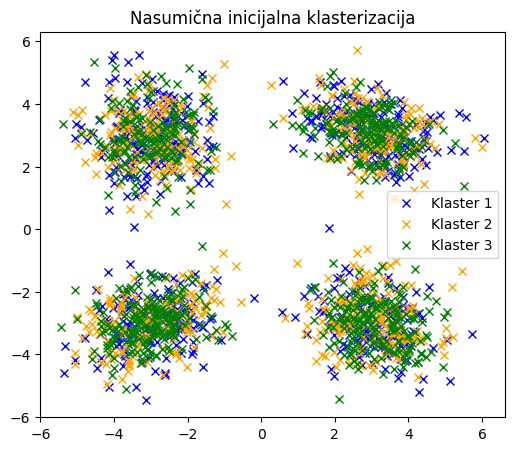

In [44]:
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 3, size=data.shape[1])

K1 = data[:, labels == 0]
K2 = data[:, labels == 1]
K3 = data[:, labels == 2]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.show()

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/2975428650.py:38: RuntimeWarning: divide by zero encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 3*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/2975428650.py:38: RuntimeWarning: overflow encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 3*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/29754

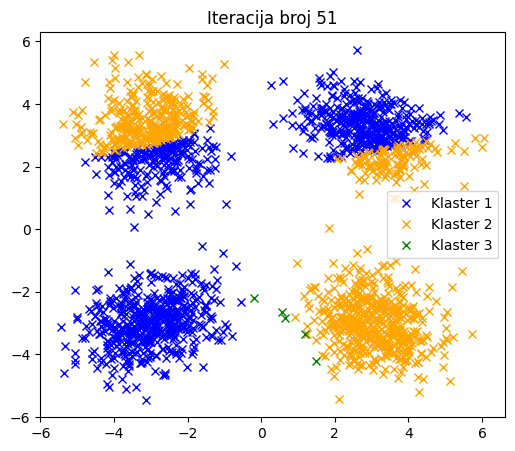

In [45]:
M1 = np.mean(K1, axis=1) 
S1 = np.cov(K1)
P1 = K1.shape[1] / (3 * N)
M2 = np.mean(K2, axis=1)
S2 = np.cov(K2)
P2 = K2.shape[1] / (3 * N)
M3 = np.mean(K3, axis=1)
S3 = np.cov(K3)
P3 = K3.shape[1] / (3 * N)

K = np.hstack((K1, K2, K3))
f1 = multivar_gauss(K, M1, S1)
f2 = multivar_gauss(K, M2, S2)
f3 = multivar_gauss(K, M3, S3)
denom = P1*f1 + P2*f2 + P3*f3 
q1 = P1 * f1 / denom
q2 = P2 * f2 / denom
q3 = P3 * f3 / denom

lmax = 50 
l = 0 
reclassified = True 
T = 1e-8

while l<lmax and reclassified:    
    P1 = np.sum(q1) / (3*N)
    P2 = np.sum(q2) / (3*N)
    P3 = np.sum(q3) / (3*N)

    M1 = np.sum(q1 * K, axis=1) / (P1 * 3*N) 
    M2 = np.sum(q2 * K, axis=1) / (P2 * 3*N)
    M3 = np.sum(q3 * K, axis=1) / (P3 * 3*N)
    
    diff1 = K - M1[:, np.newaxis]
    diff2 = K - M2[:, np.newaxis]
    diff3 = K - M3[:, np.newaxis]
    
    S1 = (diff1 * q1) @ diff1.T / (P1 * 3*N)
    S2 = (diff2 * q2) @ diff2.T / (P2 * 3*N)
    S3 = (diff3 * q3) @ diff3.T / (P3 * 3*N)

    f1 = multivar_gauss(K, M1, S1)
    f2 = multivar_gauss(K, M2, S2)
    f3 = multivar_gauss(K, M3, S3)
    
    sth = P1*f1 + P2*f2 + P3*f3 
    q1new = P1 * f1 / sth
    q2new = P2 * f2 / sth
    q3new = P3 * f3 / sth


    l+=1
    q = np.vstack([q1, q2, q3])
    qnew = np.vstack([q1new, q2new, q3new])
    if np.max(np.abs(qnew - q)) < T:
        reclassified = False
    else:
        q1 = q1new
        q2 = q2new
        q3 = q3new
        
K1, K2, K3 = [], [], []
q = np.vstack([q1new, q2new, q3new])
classes = np.argmax(q, axis=0)  

K1 = K[:, classes == 0]
K2 = K[:, classes == 1]
K3 = K[:, classes == 2]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.title(f'Iteracija broj {l+1}')
plt.legend()
plt.show()

Rezultat 4 apriorno ne znamo broj klasa (pretpostavimo da je 5)

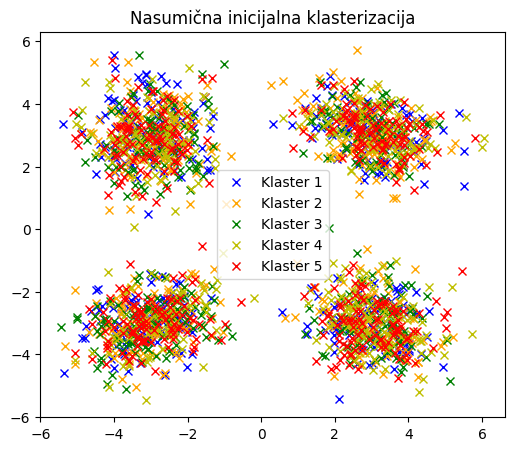

In [46]:
data = np.vstack((data1, data2, data3, data4)).T  
labels = np.random.randint(0, 5, size=data.shape[1])

K1 = data[:, labels == 0]
K2 = data[:, labels == 1]
K3 = data[:, labels == 2]
K4 = data[:, labels == 3]
K5 = data[:, labels == 4]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.plot(K4[0, :], K4[1, :], 'yx', label='Klaster 4')
plt.plot(K5[0, :], K5[1, :], 'rx', label='Klaster 5')

plt.title('Nasumična inicijalna klasterizacija')
plt.legend()
plt.show()

/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: divide by zero encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: overflow encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1362380576.py:7: RuntimeWarning: invalid value encountered in matmul
  exponent = -0.5 * np.sum(diff * (inv_cov @ diff), axis=0)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1675382950.py:55: RuntimeWarning: divide by zero encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/1675382950.py:55: RuntimeWarning: overflow encountered in matmul
  S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
/var/folders/4g/g003h3696xb2x1hx9m48dv8w0000gn/T/ipykernel_49550/16753

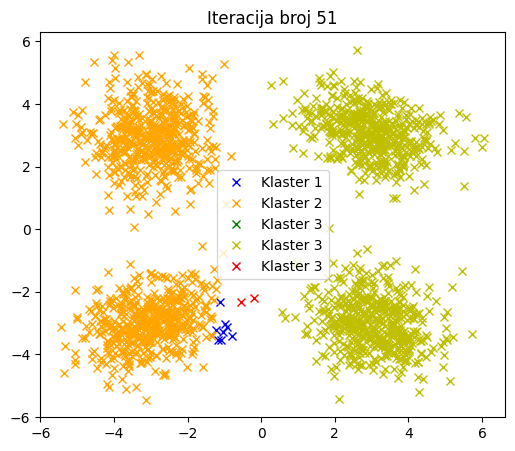

In [47]:
M1 = np.mean(K1, axis=1) 
S1 = np.cov(K1)
P1 = K1.shape[1] / (4 * N)
M2 = np.mean(K2, axis=1)
S2 = np.cov(K2)
P2 = K2.shape[1] / (4 * N)
M3 = np.mean(K3, axis=1)
S3 = np.cov(K3)
P3 = K3.shape[1] / (4 * N)
M4 = np.mean(K4, axis=1)
S4 = np.cov(K4)
P4 = K4.shape[1] / (4 * N)
M5 = np.mean(K5, axis=1)
S5 = np.cov(K5)
P5 = K5.shape[1] / (4 * N)

K = np.hstack((K1, K2, K3, K4, K5))
f1 = multivar_gauss(K, M1, S1)
f2 = multivar_gauss(K, M2, S2)
f3 = multivar_gauss(K, M3, S3)
f4 = multivar_gauss(K, M4, S4)
f5 = multivar_gauss(K, M5, S5)
denom = P1*f1 + P2*f2 + P3*f3+ P4*f4+ P5*f5 
q1 = P1 * f1 / denom
q2 = P2 * f2 / denom
q3 = P3 * f3 / denom
q4 = P4 * f4 / denom
q5 = P5 * f5 / denom


lmax = 50 
l = 0 
reclassified = True 
T = 1e-8

while l<lmax and reclassified:    
    P1 = np.sum(q1) / (4*N)
    P2 = np.sum(q2) / (4*N)
    P3 = np.sum(q3) / (4*N)
    P4 = np.sum(q4) / (4*N)
    P5 = np.sum(q5) / (4*N)

    M1 = np.sum(q1 * K, axis=1) / (P1 * 4*N) 
    M2 = np.sum(q2 * K, axis=1) / (P2 * 4*N)
    M3 = np.sum(q3 * K, axis=1) / (P3 * 4*N)
    M4 = np.sum(q4 * K, axis=1) / (P4 * 4*N)
    M5 = np.sum(q5 * K, axis=1) / (P5 * 4*N)
    
    diff1 = K - M1[:, np.newaxis]
    diff2 = K - M2[:, np.newaxis]
    diff3 = K - M3[:, np.newaxis]
    diff4 = K - M4[:, np.newaxis]
    diff5 = K - M5[:, np.newaxis]
    
    S1 = (diff1 * q1) @ diff1.T / (P1 * 4*N)
    S2 = (diff2 * q2) @ diff2.T / (P2 * 4*N)
    S3 = (diff3 * q3) @ diff3.T / (P3 * 4*N)
    S4 = (diff4 * q4) @ diff4.T / (P4 * 4*N)
    S5 = (diff5 * q5) @ diff5.T / (P5 * 4*N)

    f1 = multivar_gauss(K, M1, S1)
    f2 = multivar_gauss(K, M2, S2)
    f3 = multivar_gauss(K, M3, S3)
    f4 = multivar_gauss(K, M4, S4)
    f5 = multivar_gauss(K, M5, S5)
    
    sth = P1*f1 + P2*f2 + P3*f3  + P4*f4  + P5*f5 
    q1new = P1 * f1 / sth
    q2new = P2 * f2 / sth
    q3new = P3 * f3 / sth
    q4new = P4 * f4 / sth
    q5new = P5 * f5 / sth

    l+=1
    q = np.vstack([q1, q2, q3,q4,q5])
    qnew = np.vstack([q1new, q2new, q3new,q4new,q5new])
    if np.max(np.abs(qnew - q)) < T:
        reclassified = False
    else:
        q1 = q1new
        q2 = q2new
        q3 = q3new
        q4 = q4new  
        q5 = q5new
        
K1, K2, K3, K4, K5 = [], [], [], [], []
q = np.vstack([q1new, q2new, q3new,q4new,q5new])
classes = np.argmax(q, axis=0) 

K1 = K[:, classes == 0]
K2 = K[:, classes == 1]
K3 = K[:, classes == 2]
K4 = K[:, classes == 3]
K5 = K[:, classes == 4]

plt.figure(figsize=(6, 5))
plt.plot(K1[0, :], K1[1, :], 'bx', label='Klaster 1')
plt.plot(K2[0, :], K2[1, :],'x', color='orange', label='Klaster 2')
plt.plot(K3[0, :], K3[1, :], 'gx', label='Klaster 3')
plt.plot(K4[0, :], K4[1, :], 'yx', label='Klaster 3')
plt.plot(K5[0, :], K5[1, :], 'rx', label='Klaster 3')


plt.title(f'Iteracija broj {l+1}')
plt.legend()
plt.show()

v) Generisanje podataka iz dve nelinearno separabilne klase

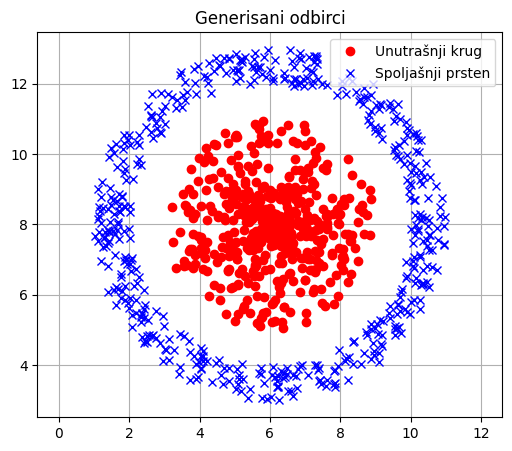

In [50]:
N = 500

# centar kružnica
C = np.array([[6], [8]])  

# unutrašnji, pun krug radijusa između 0 i 3
R1 = 3 * np.random.rand(N)       
Teta1 = 2 * np.pi * np.random.rand(N)  
X = np.vstack((R1 * np.cos(Teta1), R1 * np.sin(Teta1))) + C

# spoljašnja kružnica radijusa između 4 i 7
R2 = 4 + np.random.rand(N)       
Teta2 = 2 * np.pi * np.random.rand(N)
Y = np.vstack((R2 * np.cos(Teta2), R2 * np.sin(Teta2))) + C

plt.figure(figsize=(6, 5))
plt.plot(X[0], X[1], 'ro', label='Unutrašnji krug')
plt.plot(Y[0], Y[1], 'bx', label='Spoljašnji prsten')
plt.title('Generisani odbirci')
plt.axis('equal')
plt.grid()
plt.legend()
plt.show()

Rezultat 1 za stohastičku inicajlnu klasterizaciju sa poznatim brojem klastera

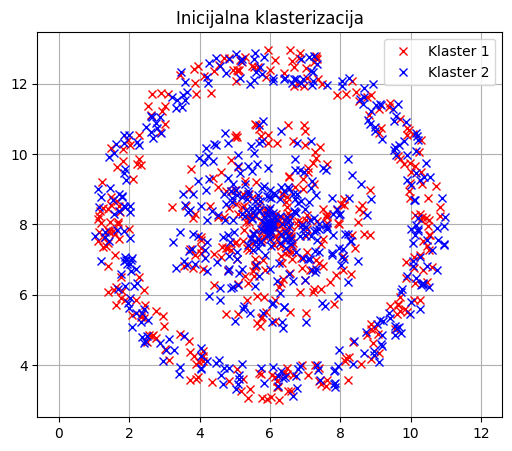

In [52]:
pom = np.random.rand(2 * N)
X1 = np.empty((X.shape[0], 0))
Y1 = np.empty((Y.shape[0], 0))

for i in range(N):
    if pom[i] < 0.5:
        X1 = np.hstack((X1, X[:, [i]]))
    else:
        Y1 = np.hstack((Y1, X[:, [i]]))

for i in range(N, 2*N):
    if pom[i] < 0.5:
        X1 = np.hstack((X1, Y[:, [i - N]]))
    else:
        Y1 = np.hstack((Y1, Y[:, [i - N]]))

plt.figure(figsize=(6, 5))
plt.plot(X1[0], X1[1], 'rx', label='Klaster 1')
plt.plot(Y1[0], Y1[1], 'bx', label='Klaster 2')
plt.axis('equal')
plt.legend()
plt.grid()
plt.title('Inicijalna klasterizacija')
plt.show()

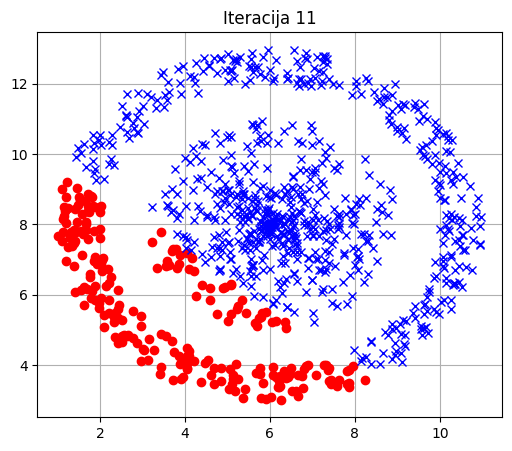

In [56]:
lmax = 100
l = 0
reclassified = True

while l < lmax and reclassified:
    M1 = np.mean(X1, axis=1, keepdims=True)
    M2 = np.mean(Y1, axis=1, keepdims=True)
    S1 = np.cov(X1)
    S2 = np.cov(Y1)
    P1 = X1.shape[1] / (2*N)
    P2 = Y1.shape[1] / (2*N)

    X1pom, Y1pom = [], []
    reclassified = False

    for i in range(np.shape(X1)[1]):
        x = X1[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        if d1 < d2:
            X1pom.append(X1[:,i])
        else:
            Y1pom.append(X1[:,i])
            reclassified = True

    for i in range(np.shape(Y1)[1]):
        x = Y1[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        if d1 < d2:
            X1pom.append(Y1[:,i])
            reclassified = True
        else:
            Y1pom.append(Y1[:,i])
   
    X1 = np.array(X1pom).T
    Y1 = np.array(Y1pom).T

    l += 1

plt.figure(figsize=(6, 5))
plt.plot(X1[0], X1[1], 'ro')
plt.plot(Y1[0], Y1[1], 'bx')
plt.title(f'Iteracija {l}')
plt.grid()
plt.show()

In [57]:
# Prosečan broj iteracija

lsum = 0
for i in range(50):
    pom = np.random.rand(2 * N)
    X1 = np.empty((X.shape[0], 0))
    Y1 = np.empty((Y.shape[0], 0))
    
    for i in range(N):
        if pom[i] < 0.5:
            X1 = np.hstack((X1, X[:, [i]]))
        else:
            Y1 = np.hstack((Y1, X[:, [i]]))
    
    for i in range(N, 2*N):
        if pom[i] < 0.5:
            X1 = np.hstack((X1, Y[:, [i - N]]))
        else:
            Y1 = np.hstack((Y1, Y[:, [i - N]]))
    lmax = 100
    l = 0
    reclassified = True
    while l < lmax and reclassified:
        M1 = np.mean(X1, axis=1, keepdims=True)
        M2 = np.mean(Y1, axis=1, keepdims=True)
        S1 = np.cov(X1)
        S2 = np.cov(Y1)
        P1 = X1.shape[1] / (2*N)
        P2 = Y1.shape[1] / (2*N)
    
        X1pom, Y1pom = [], []
        reclassified = False
    
        for i in range(np.shape(X1)[1]):
            x = X1[:,i].reshape(2,1)
            d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
            d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
            if d1 < d2:
                X1pom.append(X1[:,i])
            else:
                Y1pom.append(X1[:,i])
                reclassified = True
    
        for i in range(np.shape(Y1)[1]):
            x = Y1[:,i].reshape(2,1)
            d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
            d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
            if d1 < d2:
                X1pom.append(Y1[:,i])
                reclassified = True
            else:
                Y1pom.append(Y1[:,i])
       
        X1 = np.array(X1pom).T
        Y1 = np.array(Y1pom).T
    
        l += 1
    lsum+=l

lmid = round(lsum / 20)
print(f"Prosečan broj iteracija je {lmid}")

Prosečan broj iteracija je 60


Rezultat 2 za inicijalnu klasterizaciju koja nije potpuno stohastička

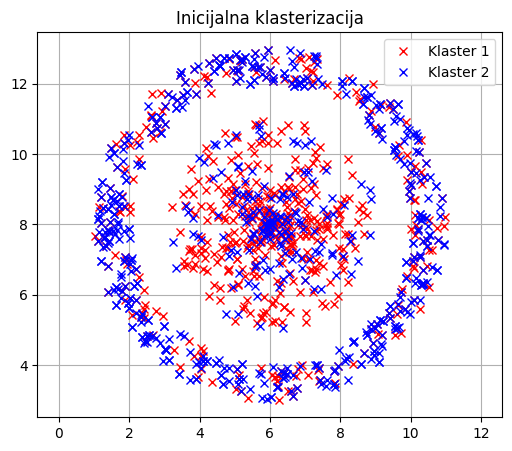

In [58]:
# U klasterima zadrzavamo prvih 200 elemenata iz svakog od njih
pom = np.random.rand(2 * N)
X1 = X[:, :200]
Y1 = Y[:, :200]

for i in range(200, N):
    if pom[i] < 0.5:
        X1 = np.hstack((X1, X[:, [i]]))
    else:
        Y1 = np.hstack((Y1, X[:, [i]]))

for i in range(N, 2*N):
    if pom[i] < 0.5:
        X1 = np.hstack((X1, Y[:, [i - N]]))
    else:
        Y1 = np.hstack((Y1, Y[:, [i - N]]))

plt.figure(figsize=(6, 5))
plt.plot(X1[0], X1[1], 'rx', label='Klaster 1')
plt.plot(Y1[0], Y1[1], 'bx', label='Klaster 2')
plt.axis('equal')
plt.legend()
plt.grid()
plt.title('Inicijalna klasterizacija')
plt.show()

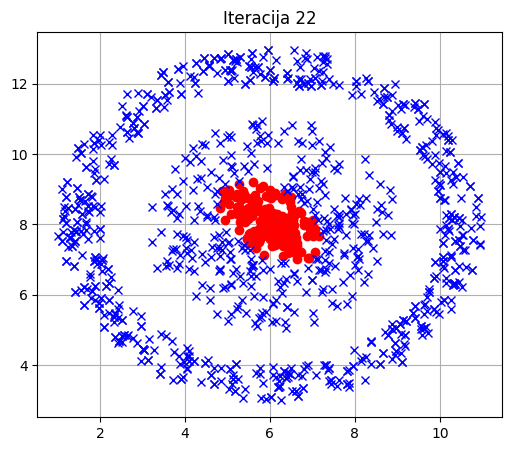

In [59]:
lmax = 100
l = 0
reclassified = True
while l < lmax and reclassified:
    M1 = np.mean(X1, axis=1, keepdims=True)
    M2 = np.mean(Y1, axis=1, keepdims=True)
    S1 = np.cov(X1)
    S2 = np.cov(Y1)
    P1 = X1.shape[1] / (2*N)
    P2 = Y1.shape[1] / (2*N)

    X1pom, Y1pom = [], []
    reclassified = False

    for i in range(np.shape(X1)[1]):
        x = X1[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        if d1 < d2:
            X1pom.append(X1[:,i])
        else:
            Y1pom.append(X1[:,i])
            reclassified = True

    for i in range(np.shape(Y1)[1]):
        x = Y1[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        if d1 < d2:
            X1pom.append(Y1[:,i])
            reclassified = True
        else:
            Y1pom.append(Y1[:,i])
   
    X1 = np.array(X1pom).T
    Y1 = np.array(Y1pom).T

    l += 1

plt.figure(figsize=(6, 5))
plt.plot(X1[0], X1[1], 'ro')
plt.plot(Y1[0], Y1[1], 'bx')
plt.title(f'Iteracija {l}')
plt.grid()
plt.show()

In [60]:
# Prosečan broj iteracija

lsum = 0
for i in range(50):
    pom = np.random.rand(2 * N)
    X1 = X[:, :200]
    Y1 = Y[:, :200]
    for i in range(200, N):
        if pom[i] < 0.5:
            X1 = np.hstack((X1, X[:, [i]]))
        else:
            Y1 = np.hstack((Y1, X[:, [i]]))
    
    for i in range(N, 2*N):
        if pom[i] < 0.5:
            X1 = np.hstack((X1, Y[:, [i - N]]))
        else:
            Y1 = np.hstack((Y1, Y[:, [i - N]]))
    lmax = 100
    l = 0
    reclassified = True
    while l < lmax and reclassified:
        M1 = np.mean(X1, axis=1, keepdims=True)
        M2 = np.mean(Y1, axis=1, keepdims=True)
        S1 = np.cov(X1)
        S2 = np.cov(Y1)
        P1 = X1.shape[1] / (2*N)
        P2 = Y1.shape[1] / (2*N)
    
        X1pom, Y1pom = [], []
        reclassified = False
    
        for i in range(np.shape(X1)[1]):
            x = X1[:,i].reshape(2,1)
            d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
            d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
            if d1 < d2:
                X1pom.append(X1[:,i])
            else:
                Y1pom.append(X1[:,i])
                reclassified = True
    
        for i in range(np.shape(Y1)[1]):
            x = Y1[:,i].reshape(2,1)
            d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
            d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
            if d1 < d2:
                X1pom.append(Y1[:,i])
                reclassified = True
            else:
                Y1pom.append(Y1[:,i])
       
        X1 = np.array(X1pom).T
        Y1 = np.array(Y1pom).T
    
        l += 1
    lsum+=l

lmid = round(lsum / 20)
print(f"Prosečan broj iteracija je {lmid}")

Prosečan broj iteracija je 54


Rezultat 3 apriorno ne znamo broj klasa (pretpostavimo da je 3)

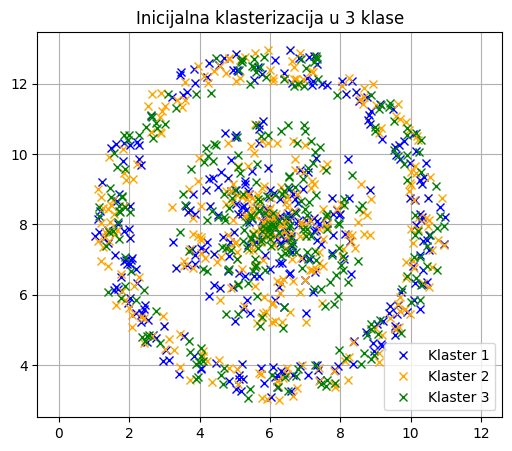

In [61]:
data = np.hstack((X, Y)) 
labels = np.random.randint(0, 3, size=data.shape[1])

K1 = data[:, labels == 0]
K2 = data[:, labels == 1]
K3 = data[:, labels == 2]

plt.figure(figsize=(6, 5))
plt.plot(K1[0], K1[1], 'bx', label='Klaster 1')
plt.plot(K2[0], K2[1], 'x', color='orange', label='Klaster 2')
plt.plot(K3[0], K3[1], 'gx', label='Klaster 3')
plt.title('Inicijalna klasterizacija u 3 klase')
plt.legend()
plt.grid()
plt.axis('equal')
plt.show()

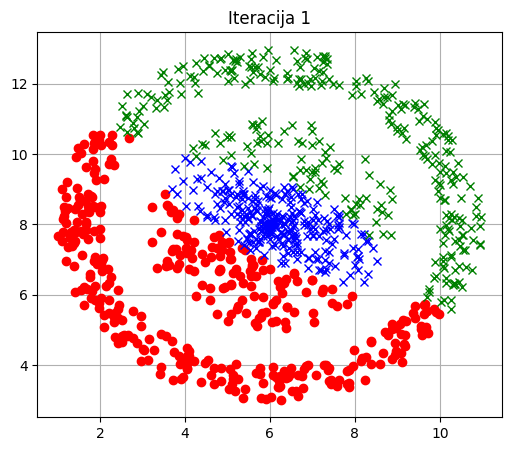

In [63]:
lmax = 100
l = 0
reclassified = True
while l < lmax and reclassified:
    M1 = np.mean(K1, axis=1, keepdims=True)
    M2 = np.mean(K2, axis=1, keepdims=True)
    M3 = np.mean(K3, axis=1, keepdims=True)
    S1 = np.cov(K1)
    S2 = np.cov(K2)
    S3 = np.cov(K3)
    P1 = K1.shape[1] / (2*N)
    P2 = K2.shape[1] / (2*N)
    P3 = K3.shape[1] / (2*N)

    K1pom, K2pom, K3pom = [], [], []
    reclassified = False

    for i in range(np.shape(K1)[1]):
        x = K1[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        d3 = 0.5 * (x-M3).T @ inv(S3) @ (x-M3) + 0.5 * np.log(det(S3)) - 0.5 * np.log(P3)
        minimum = min(d1,d2,d3)
        if d1==minimum:
            K1pom.append(K1[:,i])
        elif d2==minimum:
            K2pom.append(K1[:,i])
            reclassified = True
        else:
            K3pom.append(K1[:,i])
            reclassified = True
            
    for i in range(np.shape(K2)[1]):
        x = K2[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        d3 = 0.5 * (x-M3).T @ inv(S3) @ (x-M3) + 0.5 * np.log(det(S3)) - 0.5 * np.log(P3)
        minimum = min(d1,d2,d3)
        if d2==minimum:
            K2pom.append(K2[:,i])
        elif d1==minimum:
            K1pom.append(K2[:,i])
            reclassified = True
        else:
            K3pom.append(K2[:,i])
            reclassified = True

    for i in range(np.shape(K3)[1]):
        x = K3[:,i].reshape(2,1)
        d1 = 0.5 * (x-M1).T @ inv(S1) @ (x-M1) + 0.5 * np.log(det(S1)) - 0.5 * np.log(P1)
        d2 = 0.5 * (x-M2).T @ inv(S2) @ (x-M2) + 0.5 * np.log(det(S2)) - 0.5 * np.log(P2)
        d3 = 0.5 * (x-M3).T @ inv(S3) @ (x-M3) + 0.5 * np.log(det(S3)) - 0.5 * np.log(P3)
        minimum = min(d1,d2,d3)
        if d3==minimum:
            K3pom.append(K3[:,i])
        elif d1==minimum:
            K1pom.append(K3[:,i])
            reclassified = True
        else:
            K2pom.append(K3[:,i])
            reclassified = True
   
    K1 = np.array(K1pom).T
    K2 = np.array(K2pom).T
    K3 = np.array(K3pom).T

    l += 1

plt.figure(figsize=(6, 5))
plt.plot(K1[0], K1[1], 'ro')
plt.plot(K2[0], K2[1], 'bx')
plt.plot(K3[0], K3[1], 'gx')
plt.title(f'Iteracija {l}')
plt.grid()
plt.show()